# Buổi E3: Boosting, sửa sai từng bước

**Hiện trường.** Cậu nhân viên học việc Tí đoán giá nhà nhưng đoán chung chung, lệch nhiều. Chị Hạnh không bắt Tí học lại từ đầu. Cô làm khác: **Tí đoán trước, chị chỉ ra chỗ sai, người thứ hai chỉ học cách sửa phần sai đó, người thứ ba sửa phần còn sai sau người thứ hai, và cứ thế**. Cuối cùng cộng mọi phần sửa lại.

Đó là **boosting** (tăng cường): mô hình xếp **nối tiếp**, mỗi cái học **phần sai còn lại** của các cái trước. Khác bagging (E1: nhiều cây độc lập, bỏ phiếu **song song**).

**Mindset của người làm dữ liệu:** bagging chữa phương sai cao (cây quá thất thường); boosting chữa **thiên lệch cao** (mô hình quá đơn giản) bằng cách **chồng nhiều mô hình rất đơn giản** lên nhau, và vì vậy **có thể quá khớp** nếu chồng quá nhiều.

**Lưu ý:** dữ liệu sinh ngẫu nhiên hoặc mẫu để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: một nhát cắt và 100 nhát cắt chồng nhau |
| Chặng 1 | Tự làm boosting bằng tay: tính phần sai, học phần sai |
| Chặng 2 | Tốc độ học và số vòng: đi bước nhỏ, đi nhiều bước |
| Chặng 3 | Boosting quá khớp: biết dừng đúng lúc |
| Chặng 4 | Đối chiếu hàng sẵn của sklearn |
| Chặng 5 | Điểm yếu: nhãn nhiễu, và boosting so với bagging |

## Chặng 0: Thấy ngay, một nhát cắt và 100 nhát cắt chồng nhau

**Câu hỏi:** một mô hình cực đơn giản (chỉ một nhát cắt) có làm được gì?

Dữ liệu: đường sóng `sin` có nhiễu, 150 điểm (dựng có chủ đích để vẽ được). Mỗi mô hình thành viên là **gốc cây** (*decision stump*): cây chỉ sâu **một tầng**, đoán hai mức. Một mình nó rất yếu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

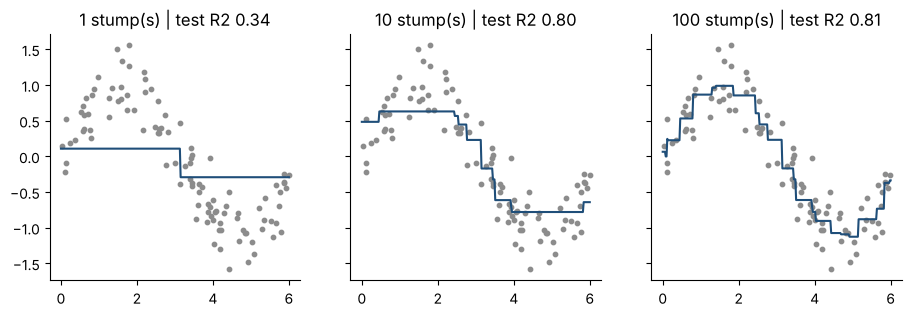

In [2]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0, 6, 150))
y = np.sin(x) + rng.randn(150) * 0.3
X = x[:, None]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
grid = np.linspace(0, 6, 300)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, n_rounds in zip(axes, [1, 10, 100]):
    gb = GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=0.3, max_depth=1, random_state=0).fit(X_train, y_train)
    ax.scatter(X_train, y_train, color=GRAY, s=10); ax.plot(grid, gb.predict(grid), color=BLUE)
    ax.set_title(f"{n_rounds} stump(s) | test R2 {gb.score(X_test, y_test):.2f}")
plt.show()

**Giải thích từng dòng**

- `x[:, None]`: đổi dãy 150 số thành bảng 150 hàng × 1 cột (sklearn cần `X` hai chiều).
- `GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=0.3, max_depth=1)`: boosting cho bài toán số. `n_estimators` là số vòng sửa sai, `learning_rate` là phần của mỗi lần sửa được cộng vào (chặng 2), `max_depth=1` nghĩa là mỗi thành viên là gốc cây.
- `zip(axes, [1, 10, 100])`: ghép mỗi khung hình với một số vòng.
- `gb.predict(grid)`: đường dự đoán trên 300 điểm đều nhau để vẽ thành đường.

**Cách đọc.**
- **Hình trái (1 nhát cắt):** chỉ hai mức, một bậc thang.
- **Hình giữa (10):** vài bậc, bắt đầu theo hình sóng.
- **Hình phải (100):** đường **uốn lượn theo sóng** dù mỗi mô hình thành viên chỉ biết cắt một nhát.
- **Bức tranh:** cộng nhiều bậc thang nhỏ cho ra đường cong. Mỗi nhát cắt sửa một phần phần sai còn lại.
- **Câu hỏi tiếp:** "phần sai còn lại" là gì, và ai học nó?

**Mang về chặng 0:** nhiều mô hình rất yếu, mỗi cái sửa phần sai của các cái trước, cộng lại thành một mô hình mạnh.

## Chặng 1: Tự làm boosting bằng tay

**Câu hỏi:** "học phần sai" cụ thể là làm gì?

Đời thường, từng bước:

1. Đoán ban đầu: **mức trung bình** của `y` cho mọi điểm.
2. Tính **phần sai** (*residual*) = thực tế - đoán hiện tại.
3. Huấn luyện một gốc cây để **đoán phần sai** (mục tiêu mới là phần sai, không phải `y`).
4. Cộng **một phần** của dự đoán gốc cây vào đoán hiện tại.
5. Quay lại bước 2.

In [3]:
from sklearn.tree import DecisionTreeRegressor
lr = 0.3
pred = np.full(len(y_train), y_train.mean())
stumps = []
for round_ in range(100):
    resid = y_train - pred
    stump = DecisionTreeRegressor(max_depth=1).fit(X_train, resid)
    pred = pred + lr * stump.predict(X_train)
    stumps.append(stump)
    if round_ in (0, 1, 2, 9, 99):
        print("after round", round_ + 1, "| train MSE:", round(np.mean((y_train - pred) ** 2), 4))
print("baseline (just the mean) MSE:", round(np.mean((y_train - y_train.mean()) ** 2), 4))

after round 1 | train MSE: 0.3726
after round 2 | train MSE: 0.2539
after round 3 | train MSE: 0.1902
after round 10 | train MSE: 0.1025
after round 100 | train MSE: 0.0494
baseline (just the mean) MSE: 0.5971


**Giải thích từng dòng**

- `pred = np.full(len(y_train), y_train.mean())`: bước 1: ai cũng đoán bằng trung bình.
- `resid = y_train - pred`: bước 2: phần sai còn lại sau các vòng trước.
- `DecisionTreeRegressor(max_depth=1).fit(X_train, resid)`: bước 3: gốc cây học **đoán phần sai**. Chú ý nhãn của nó là `resid`, không phải `y_train`.
- `pred = pred + lr * stump.predict(X_train)`: bước 4: cộng **một phần** (`lr` = 0,3) dự đoán của gốc cây vào đoán hiện tại.
- `np.mean((y_train - pred) ** 2)`: sai số bình phương trung bình (MSE): càng nhỏ càng tốt.

In [4]:
def boosted_predict(X_new, stumps, base, lr):
    out = np.full(len(X_new), base)
    for s in stumps:
        out = out + lr * s.predict(X_new)
    return out
mine = boosted_predict(X_test, stumps, y_train.mean(), lr)
print("my boosting, test MSE:", round(np.mean((y_test - mine) ** 2), 4), "| noise floor (0.3^2):", 0.09)

my boosting, test MSE: 0.1013 | noise floor (0.3^2): 0.09


**Giải thích từng dòng**

- `def boosted_predict(X_new, stumps, base, lr):`: để đoán điểm mới: bắt đầu từ mức trung bình rồi cộng phần sửa của **mọi** gốc cây theo đúng thứ tự.
- `0.3^2`: nhiễu ta cố ý thêm có độ lệch 0,3 nên sai số trung bình trên dữ liệu mới **khó thấp hơn** khoảng 0,09; đây là "trần". Tập thi chỉ vài chục điểm nên đôi khi đo ra thấp hơn chút nhờ may mắn.

**Cách đọc.**
- **Con số:** sai số học từ **0,597** (đoán trung bình) giảm dần qua các vòng. Trên tập thi, MSE **0,101**; trần do nhiễu khoảng 0,09.
- **Bức tranh:** mỗi vòng, gốc cây nhìn vào chỗ **còn sai nhiều nhất** và vá một mảng. Vòng đầu vá rộng, các vòng sau vá chi tiết. Cái ta vừa viết là **toàn bộ ruột** của gradient boosting cho hàm sai số bình phương (tên "gradient" đến từ việc phần sai chính là hướng giảm sai số).
- **Câu hỏi tiếp:** hệ số 0,3 và số vòng 100 là các núm; chúng ảnh hưởng thế nào?

**Mang về chặng 1:** boosting = đoán ban đầu + nhiều vòng "học phần sai còn lại, cộng một phần vào".

## Chặng 2: Tốc độ học và số vòng

**Câu hỏi:** `learning_rate` (hệ số cộng mỗi vòng) và số vòng đổi nhau thế nào?

Đời thường: đi xuống đồi trong sương. Bước dài (hệ số 1) thì nhanh nhưng dễ vượt quá; bước ngắn (0,05) thì an toàn nhưng cần nhiều bước hơn. Ta vẽ sai số **thi** theo số vòng cho ba tốc độ.

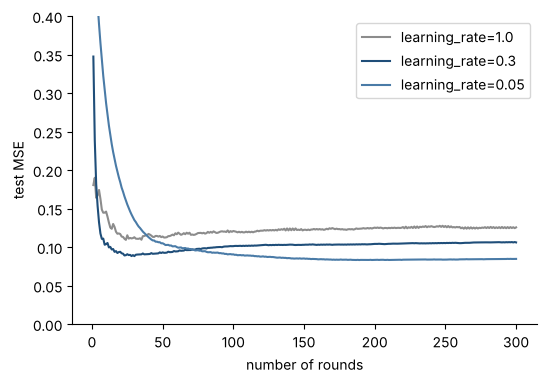

In [5]:
def staged_test_mse(lr, rounds=300):
    gb = GradientBoostingRegressor(n_estimators=rounds, learning_rate=lr, max_depth=1, random_state=0).fit(X_train, y_train)
    return [np.mean((y_test - p) ** 2) for p in gb.staged_predict(X_test)], [np.mean((y_train - p) ** 2) for p in gb.staged_predict(X_train)]
fig, ax = plt.subplots()
curves = {}
for lr_, color in [(1.0, GRAY), (0.3, BLUE), (0.05, "#4A7BA7")]:
    te, tr = staged_test_mse(lr_)
    curves[lr_] = (te, tr)
    ax.plot(range(1, 301), te, color=color, label=f"learning_rate={lr_}")
ax.set_xlabel("number of rounds"); ax.set_ylabel("test MSE"); ax.set_ylim(0, 0.4); ax.legend()
plt.show()

**Giải thích từng dòng**

- `gb.staged_predict(X_test)`: trả về dự đoán **sau từng vòng** (vòng 1, vòng 2, ...) chỉ trong một lần học: tiện để vẽ đường theo số vòng.
- `[... for p in ...]`: với dự đoán sau mỗi vòng, tính MSE; ra một danh sách 300 số.
- `ax.set_ylim(0, 0.4)`: cắt trục y để thấy rõ phần đáy (các đường rất cao lúc đầu).

**Cách đọc.**
- **Con số:** sai số thi thấp nhất cho hệ số 1,0: **0,109** (ở vòng 24); cho 0,3: **0,088** (vòng 30); cho 0,05: **0,083** (vòng 189).
- **Bức tranh:** hệ số lớn **xuống nhanh nhưng đáy nông rồi tăng lại**; hệ số nhỏ **xuống chậm nhưng thường cho đáy thấp hơn** và đường êm hơn. Quy tắc nghề: chọn hệ số **nhỏ** (0,05 đến 0,1) rồi dùng **nhiều vòng**, đổi thời gian lấy độ ổn định.
- **Câu hỏi tiếp:** các đường đều **tăng lại** ở bên phải. Vì sao, và làm sao dừng đúng chỗ?

**Mang về chặng 2:** `learning_rate` nhỏ cần nhiều vòng hơn nhưng thường tốt hơn; hai núm này đi cặp.

## Chặng 3: Boosting quá khớp, biết dừng đúng lúc

**Câu hỏi:** thêm vòng thì sai số học luôn giảm; sai số thi thì sao?

Khác bagging (thêm cây không hại), **boosting có thể quá khớp**: vòng càng nhiều, nó càng vá cả **nhiễu** trong dữ liệu học. Cách dừng: theo dõi một phần dữ liệu **xác nhận** và dừng khi sai số ở đó thôi giảm. sklearn làm sẵn với `n_iter_no_change`.

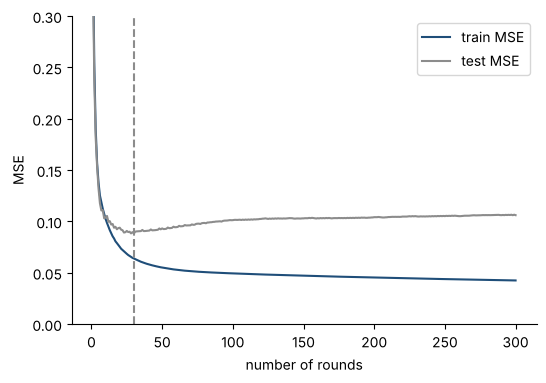

best round on test (for reference): 30 | early stopping used 67 rounds | its test MSE: 0.0823


In [6]:
te, tr = curves[0.3]
fig, ax = plt.subplots()
ax.plot(range(1, 301), tr, color=BLUE, label="train MSE"); ax.plot(range(1, 301), te, color=GRAY, label="test MSE")
ax.axvline(int(np.argmin(te)) + 1, color=GRAY, linestyle="--")
ax.set_xlabel("number of rounds"); ax.set_ylabel("MSE"); ax.set_ylim(0, 0.3); ax.legend()
plt.show()
early = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.3, max_depth=1, validation_fraction=0.2, n_iter_no_change=10, random_state=0).fit(X_train, y_train)
print("best round on test (for reference):", int(np.argmin(te)) + 1, "| early stopping used", early.n_estimators_, "rounds | its test MSE:", round(np.mean((y_test - early.predict(X_test)) ** 2), 4))

**Giải thích từng dòng**

- `validation_fraction=0.2`: tự để riêng 20% phần học làm "đề xác nhận" **bên trong** (không đụng tập thi).
- `n_iter_no_change=10`: nếu sai số xác nhận **không cải thiện trong 10 vòng liền** thì dừng. Gọi là **dừng sớm** (*early stopping*).
- `early.n_estimators_`: số vòng thực tế đã chạy trước khi dừng (nhỏ hơn 1000).
- `np.argmin(te) + 1`: vòng cho sai số thi thấp nhất (chỉ để đối chiếu; thực tế ta không được nhìn tập thi để chọn).

**Cách đọc.**
- **Con số:** sai số thi thấp nhất ở vòng **30**; dừng sớm tự dừng ở vòng **67** với MSE thi **0,082**.
- **Bức tranh:** đường xanh (học) đi xuống mãi, đường xám (thi) chạm đáy rồi **nhích lên**: khoảng cách mở ra là dấu hiệu quá khớp. Tập thi chỉ có 45 điểm, nên đáy khá nông và dao động.
- **Thói quen tốt:** đặt `n_estimators` lớn, bật `n_iter_no_change`, để máy tự dừng.

**Mang về chặng 3:** boosting quá khớp khi chồng quá nhiều vòng; dùng dừng sớm với phần xác nhận nội bộ.

## Chặng 4: Đối chiếu hàng sẵn của sklearn

**Câu hỏi:** bản tự viết ở chặng 1 có giống `GradientBoostingRegressor` không?

Với hàm sai số bình phương, khởi đầu bằng trung bình và gốc cây, hai bản phải **cho cùng dự đoán**.

In [7]:
ref = GradientBoostingRegressor(n_estimators=100, learning_rate=0.3, max_depth=1, random_state=0).fit(X_train, y_train)
print("max difference between my predictions and sklearn's:", float(np.abs(ref.predict(X_test) - mine).max()))
print("same prediction:", bool(np.allclose(ref.predict(X_test), mine)))

max difference between my predictions and sklearn's: 0.0
same prediction: True


**Giải thích từng dòng**

- `np.abs(a - b).max()`: chênh lệch lớn nhất giữa hai dãy dự đoán.
- `np.allclose(a, b)`: hai dãy có trùng nhau (trong sai số làm tròn) không.

**Cách đọc.** Chênh lệch lớn nhất **0.00e+00**; trùng nhau: **True**. Bản tự viết và bản của thư viện là **cùng một thuật toán**; thư viện chỉ thêm tốc độ, thêm hàm sai số khác và các tính năng (dừng sớm, lấy mẫu con).

**Mang về chặng 4:** gradient boosting không phải phép thuật; nó là vòng lặp "tính phần sai, học phần sai, cộng một phần".

## Chặng 5: Điểm yếu, nhãn nhiễu, và boosting so với bagging

**Câu hỏi:** boosting có tốt hơn rừng trong mọi trường hợp?

Boosting **dồn sức vào chỗ còn sai**. Nếu chỗ sai là **nhãn bị gán nhầm**, nó sẽ cố học cái sai đó. Thí nghiệm: hai vầng trăng, so rừng và boosting khi nhãn **sạch** và khi **15% nhãn bị đổi ngẫu nhiên** (dựng có chủ đích).

In [8]:
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
Xm, ym = make_moons(n_samples=600, noise=0.25, random_state=1)
rng = np.random.RandomState(2)
flip = rng.rand(len(ym)) < 0.15
ym_noisy = np.where(flip, 1 - ym, ym)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
rows = []
for label, yy in [("clean labels", ym), ("15% labels flipped", ym_noisy)]:
    for name, m in [("random forest", RandomForestClassifier(n_estimators=200, random_state=0)), ("gradient boosting", GradientBoostingClassifier(n_estimators=300, learning_rate=0.3, max_depth=3, random_state=0))]:
        rows.append({"data": label, "model": name, "CV accuracy": cross_val_score(m, Xm, yy, cv=cv, n_jobs=-1).mean()})
noise_table = pd.DataFrame(rows)
print(noise_table.round(3).to_string(index=False))

              data             model  CV accuracy
      clean labels     random forest        0.926
      clean labels gradient boosting        0.919
15% labels flipped     random forest        0.782
15% labels flipped gradient boosting        0.744


**Giải thích từng dòng**

- `np.where(flip, 1 - ym, ym)`: chỗ nào `flip` đúng thì đảo nhãn (0 thành 1, 1 thành 0), chỗ khác giữ nguyên.
- `GradientBoostingClassifier(..., max_depth=3)`: boosting cho phân loại; ở đây dùng cây sâu 3 thay vì gốc cây để đủ sức. Đánh giá bằng kiểm định chéo lặp (D1).

**Cách đọc.**
- **Con số:** nhãn sạch: rừng **92,6%**, boosting **91,9%**. Nhãn nhiễu 15%: rừng **78,2%**, boosting **74,4%**. (Điểm được chấm trên nhãn nhiễu nên đều thấp hơn.)
- **Bức tranh:** so sánh **mức tụt** của hai mô hình khi nhãn nhiễu: rừng tụt 14,4 điểm, boosting tụt 17,4 điểm. Boosting thường **nhạy với nhãn sai hơn** vì nó đuổi theo phần sai.

| | Bagging và rừng | Boosting |
|---|---|---|
| Cách ghép | song song, độc lập | nối tiếp, cái sau sửa cái trước |
| Thành viên | cây sâu, thất thường | cây nông, yếu |
| Chữa bệnh | phương sai cao | thiên lệch cao |
| Thêm vòng | không quá khớp | **có thể quá khớp** |
| Núm chính | số cây, `max_features` | `learning_rate` + số vòng, `max_depth` |
| Nhãn nhiễu | khá bền | nhạy hơn |

**Mang về chặng 5:** boosting mạnh nhưng nhạy với nhãn sai và cần dừng đúng lúc; rừng bền, ít núm, dễ dùng.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Nhiều gốc cây yếu chồng lên nhau cho ra đường cong. |
| 1 | Boosting = đoán ban đầu + nhiều vòng học phần sai rồi cộng một phần. |
| 2 | `learning_rate` nhỏ + nhiều vòng thường tốt hơn; hai núm đi cặp. |
| 3 | Boosting có thể quá khớp; dùng dừng sớm. |
| 4 | Bản tự viết trùng bản của sklearn: không có phép thuật. |
| 5 | Boosting nhạy nhãn nhiễu; rừng bền hơn. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Người sau sửa sai của người trước | boosting | `GradientBoostingRegressor` |
| Phần còn sai | phần dư (residual) | `resid = y - pred` |
| Mô hình thành viên chỉ cắt một nhát | gốc cây (stump) | `max_depth=1` |
| Phần của mỗi lần sửa được cộng | tốc độ học | `learning_rate` |
| Số lần sửa | số vòng | `n_estimators` |
| Dừng khi không còn cải thiện | dừng sớm | `n_iter_no_change` |
| Dự đoán sau từng vòng | dự đoán theo giai đoạn | `staged_predict` |

**Thử thách tự làm**

1. Ở chặng 1, đổi `lr` thành 0,05 và chạy 300 vòng. So sai số thi với `lr = 0,3`.
2. Đổi `max_depth` thành 3 ở chặng 0. Với 1 vòng và 100 vòng, hình dạng đường khác thế nào?
3. Thêm `subsample=0.5` cho `GradientBoostingRegressor` (mỗi vòng chỉ học trên nửa dữ liệu). Đường xanh lẫn xám đổi ra sao?
4. Ở chặng 5, tăng tỉ lệ nhãn nhiễu lên 30%. Mô hình nào tụt nhiều hơn?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tự tính phần dư và thêm một vòng boosting bằng tay.
- [ ] Giải thích vai trò của `learning_rate` và số vòng.
- [ ] Dùng dừng sớm để chọn số vòng.
- [ ] Phân biệt bagging và boosting qua bảng so sánh.
- [ ] Nói được khi nào boosting dễ gặp rắc rối.

## Phần thưởng (Tip pro): AdaBoost: boosting kiểu đổi trọng số


Có một cách boosting khác tên là **AdaBoost** (`sklearn.ensemble.AdaBoostClassifier`): thay vì học "phần dư", nó tăng **trọng số** của các ca vừa bị đoán sai để mô hình sau **chú ý** hơn. Cùng tinh thần "cái sau sửa cái trước" nhưng cách làm khác. Gradient boosting tổng quát hơn (đổi được hàm sai số, dùng cho cả hồi quy) và hiện phổ biến hơn.